# Exploratory Data Analysis & Machine Learning Blueprint
## Spotify Top 200 Tracks & Lyrical Trajectory Modeling

This notebook performs exploratory data analysis (EDA) on English-language Spotify Top 200 tracks and establishes the empirical foundation for modeling chart success (`best_rank_this_year <= 50`) using metadata baselines and BERT lyrical representations.

## 1. Environment Setup & Scientific Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from collections import Counter, defaultdict, deque
from sklearn.model_selection import StratifiedGroupKFold
import warnings
warnings.filterwarnings('ignore')

# Visual style setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 11

print("Scientific libraries loaded and plotting styles configured.")

Scientific libraries loaded and plotting styles configured.


## 2. Data Hygiene & Cohort Filtering (EDA-Level Filtering)

We load the complete 709-row English dataset and apply three rigorous data hygiene steps to define a clean, stationary analysis cohort:
1. **Track Deduplication:** Multiple releases for the same song (e.g., remixes, album vs single editions) are aggregated into a single entity ($709 \rightarrow 669$ tracks), taking the best rank and summed streams.
2. **Exclusion of Exogenous Seasonal & Event Tracks:** Seasonal holiday carols ($n=72$) and one-off event anthems ($n=1$, e.g., World Cup song) are filtered out. These tracks enter the annual Top 200 due to brief external calendar spikes rather than steady musical competition, distorting lyric-based predictive models.
3. **Genre Harmonization:** `Hip-Hop` and `Hip-Hop/Rap` are consolidated into a single category ($n=66$).

This yields a stationary **Standard Corpus of 596 charting tracks**.

In [2]:
# Ingest raw dataset
raw_df = pd.read_csv('spotify_data/final_dataset_for_ml_lyrics_en.csv')

# 1. Track Deduplication
agg_rules = {
    'best_rank_this_year': 'min',
    'all_time_peak_rank': 'min',
    'all_time_weeks_on_chart': 'max',
    'total_streams_this_year': 'sum',
    'release_year': 'first',
    'genre': 'first',
    'language': 'first',
    'track_type': 'first',
    'lyrics': 'first',
    'lemmas': 'first',
    'cleaned_lyrics_transformer': 'first',
    'word_count': 'first',
    'lexical_diversity': 'first',
    'lemma_word_count': 'first',
    'lemma_lexical_diversity': 'first'
}
for col in ['raw_word_count', 'raw_lexical_diversity', 'repetition_rate']:
    if col in raw_df.columns:
        agg_rules[col] = 'first'

df_dedup = raw_df.groupby(['artist_names', 'track_name'], as_index=False).agg(agg_rules)

# 2. Exclude seasonal holiday & event tracks
df = df_dedup[~df_dedup['track_type'].isin(['holiday', 'event_anthem'])].copy()

# 3. Clean subgenres and define temporal era
df['genre_cleaned'] = df['genre'].fillna('Unknown').replace({'Hip-Hop': 'Hip-Hop/Rap', 'Christmas: Classic': 'Holiday'})
df['era'] = df['release_year'].apply(lambda y: 'Contemporary (2024+)' if y >= 2024 else 'Catalog (<2024)')
df['target_hit'] = (df['best_rank_this_year'] <= 50).astype(int)

print(f"1. Raw Records: {len(raw_df)} rows")
print(f"2. After Deduplication: {len(df_dedup)} unique songs")
print(f"3. Excluded Exogenous Tracks: {(len(df_dedup) - len(df))} (Holiday: {(df_dedup['track_type'] == 'holiday').sum()}, Event: {(df_dedup['track_type'] == 'event_anthem').sum()})")
print(f"4. Final Clean Standard Corpus: {len(df)} tracks | Target y=1 (Top 50): {df['target_hit'].mean():.1%} ({df['target_hit'].sum()} tracks)")

1. Raw Records: 709 rows
2. After Deduplication: 669 unique songs
3. Excluded Exogenous Tracks: 73 (Holiday: 72, Event: 1)
4. Final Clean Standard Corpus: 596 tracks | Target y=1 (Top 50): 38.9% (232 tracks)


## 3. Temporal Distribution: Release Year as a Mandatory Control Variable

Catalog tracks (< 2024) and Contemporary tracks (2024+) exhibit fundamentally different peak rank distributions. 
Contemporary tracks reach significantly higher peaks (median rank: 46.0 vs 99.0 for catalog tracks, Mann-Whitney $p < 0.001$). 
Consequently, `release_year` and `era` must be included as primary control features in Baseline Model 1 (M1).


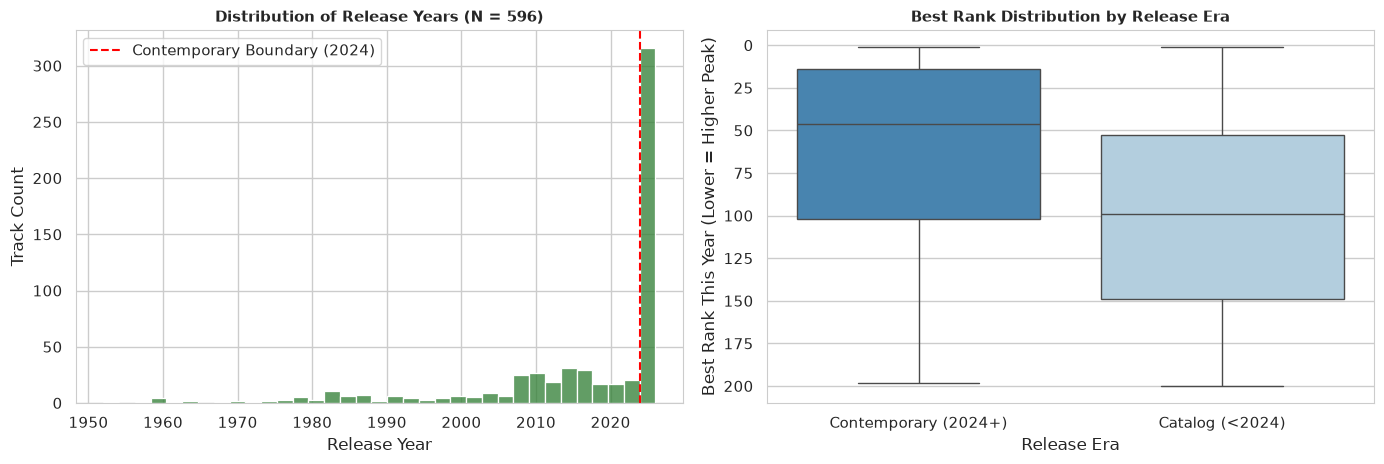

Contemporary (N=316): Median Rank = 46 | Catalog (N=280): Median Rank = 99
Mann-Whitney U Test: p-value = 7.9914e-14 (< 0.001)
Takeaway: Release year is strongly associated with peak rank and must be controlled in M1.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Release Year distribution
sns.histplot(df['release_year'].dropna(), bins=35, color="#2E7D32", ax=axes[0])
axes[0].set_title("Distribution of Release Years (N = 596)", fontweight="bold")
axes[0].set_xlabel("Release Year")
axes[0].set_ylabel("Track Count")
axes[0].axvline(2024, color='red', linestyle='--', label='Contemporary Boundary (2024)')
axes[0].legend()

# Best Rank by Era boxplot
sns.boxplot(data=df, x='era', y='best_rank_this_year', ax=axes[1], hue='era', palette="Blues_r", legend=False)
axes[1].set_title("Best Rank Distribution by Release Era", fontweight="bold")
axes[1].set_xlabel("Release Era")
axes[1].set_ylabel("Best Rank This Year (Lower = Higher Peak)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

rec_ranks = df[df['era'] == 'Contemporary (2024+)']['best_rank_this_year']
cat_ranks = df[df['era'] == 'Catalog (<2024)']['best_rank_this_year']
_, p_val = stats.mannwhitneyu(rec_ranks, cat_ranks)

print(f"Contemporary (N={len(rec_ranks)}): Median Rank = {rec_ranks.median():.0f} | Catalog (N={len(cat_ranks)}): Median Rank = {cat_ranks.median():.0f}")
print(f"Mann-Whitney U Test: p-value = {p_val:.4e} (< 0.001)")
print("Takeaway: Release year is strongly associated with peak rank and must be controlled in M1.")

## 4. Linguistic Surface Features & Frequent Vocabulary Expressions

We analyze surface lyric length (`word_count`), chorus repetition / Type-Token Ratio (`lexical_diversity`), and prevalent vocabulary.
Prevalence is measured by **Document Frequency** (percentage of distinct songs containing each lemma/phrase) after filtering non-lexical vocables (`oh`, `yeah`) and conversational light verbs (`get`, `know`, `go`).

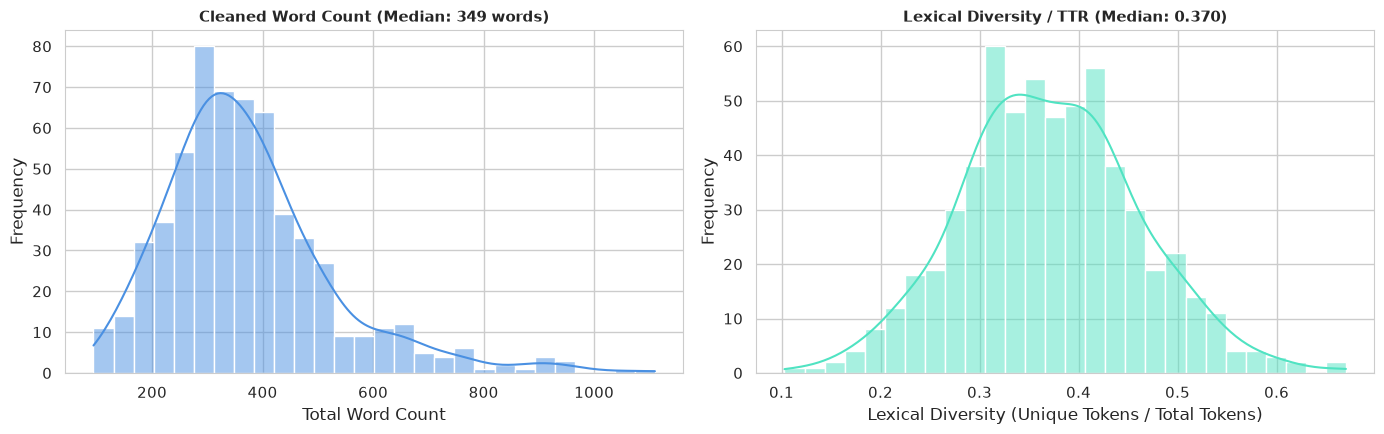

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df['word_count'], bins=28, kde=True, color="#4A90E2", ax=axes[0])
axes[0].set_title(f"Cleaned Word Count (Median: {df['word_count'].median():.0f} words)", fontweight="bold")
axes[0].set_xlabel("Total Word Count")
axes[0].set_ylabel("Frequency")

sns.histplot(df['lexical_diversity'], bins=28, kde=True, color="#50E3C2", ax=axes[1])
axes[1].set_title(f"Lexical Diversity / TTR (Median: {df['lexical_diversity'].median():.3f})", fontweight="bold")
axes[1].set_xlabel("Lexical Diversity (Unique Tokens / Total Tokens)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

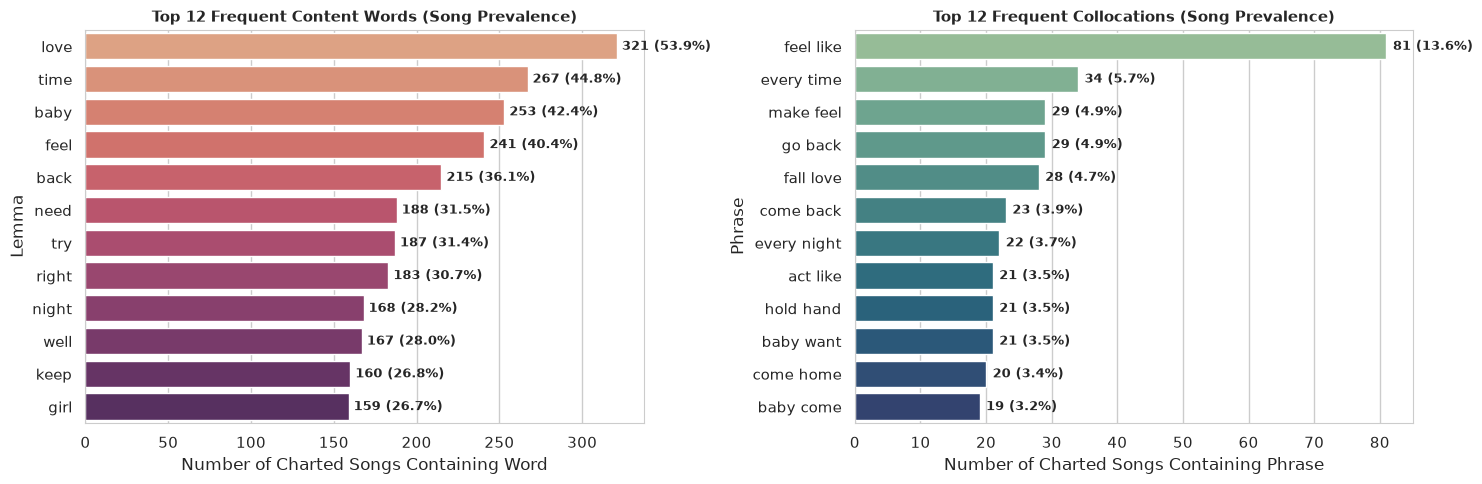

In [5]:
VOCAL_FILLERS = {
    'doo', 'mm', 'ba', 'la', 'da', 'na', 'ha', 'oh', 'yeah', 'ooh', 'uh', 'ah', 
    'woah', 'hey', 'ayy', 'ya', 'yo', 'mmm', 'hmm', 'whoa', 'huh', 'dum', 'ta', 'boom'
}
LIGHT_VERBS = {
    'get', 'know', 'go', 'want', 'say', 'make', 'let', 'take', 'come', 'like', 
    'see', 'think', 'tell', 'look', 'give', 'one', 'never', 'cause', 'would', 'could', 'way'
}

# 1. Unigrams (Document Frequency)
unigram_doc_counts = Counter()
for lemma_text in df['lemmas'].dropna().astype(str):
    content_words = set(w for w in lemma_text.split() if w not in VOCAL_FILLERS and w not in LIGHT_VERBS and len(w) > 2)
    unigram_doc_counts.update(content_words)

u_df = pd.DataFrame(unigram_doc_counts.most_common(12), columns=['Lemma', 'Song_Count'])
u_df['Percentage'] = (u_df['Song_Count'] / len(df) * 100).round(1)

# 2. Bigrams (Document Frequency)
bigram_doc_counts = Counter()
for lemma_text in df['lemmas'].dropna().astype(str):
    words = [w for w in lemma_text.split() if w not in VOCAL_FILLERS and len(w) > 1]
    song_bigrams = set()
    for i in range(len(words) - 1):
        w1, w2 = words[i], words[i+1]
        if w1 != w2 and not (w1 in LIGHT_VERBS and w2 in LIGHT_VERBS):
            song_bigrams.add(f"{w1} {w2}")
    bigram_doc_counts.update(song_bigrams)

b_df = pd.DataFrame(bigram_doc_counts.most_common(12), columns=['Phrase', 'Song_Count'])
b_df['Percentage'] = (b_df['Song_Count'] / len(df) * 100).round(1)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=u_df, x='Song_Count', y='Lemma', ax=axes[0], hue='Lemma', palette="flare", legend=False)
axes[0].set_title("Top 12 Frequent Content Words (Song Prevalence)", fontweight="bold")
axes[0].set_xlabel("Number of Charted Songs Containing Word")
for i, (cnt, pct) in enumerate(zip(u_df['Song_Count'], u_df['Percentage'])):
    axes[0].text(cnt + 3, i, f"{cnt} ({pct}%)", va='center', fontsize=9, fontweight="bold")

sns.barplot(data=b_df, x='Song_Count', y='Phrase', ax=axes[1], hue='Phrase', palette="crest", legend=False)
axes[1].set_title("Top 12 Frequent Collocations (Song Prevalence)", fontweight="bold")
axes[1].set_xlabel("Number of Charted Songs Containing Phrase")
for i, (cnt, pct) in enumerate(zip(b_df['Song_Count'], b_df['Percentage'])):
    axes[1].text(cnt + 1, i, f"{cnt} ({pct}%)", va='center', fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Statistical Hypothesis Testing & Target Neutrality

### Target-Level Hypothesis: Do Surface Metrics Differentiate Top 50 Hits?
We test whether Top 50 hits ($y = 1$, $n = 232$) differ from lower-charting tracks ($y = 0$, $n = 364$) in word count or lexical diversity.
* **Findings:** Mann-Whitney tests show $p = 0.4488$ for word count and $p = 0.3121$ for lexical diversity.
* **Statistical Meaning:** $p > 0.05$ indicates *no empirical evidence of difference*. Surface metrics cannot differentiate hits from non-hits, providing empirical justification for semantic representations (BERT).
* **Correlation:** Spearman rank correlation confirms virtually zero monotonic relationship with rank ($r_s \approx 0$). Collinearity between `word_count` and `lemma_word_count` ($r_s = 0.894$) requires retaining only one in modeling.


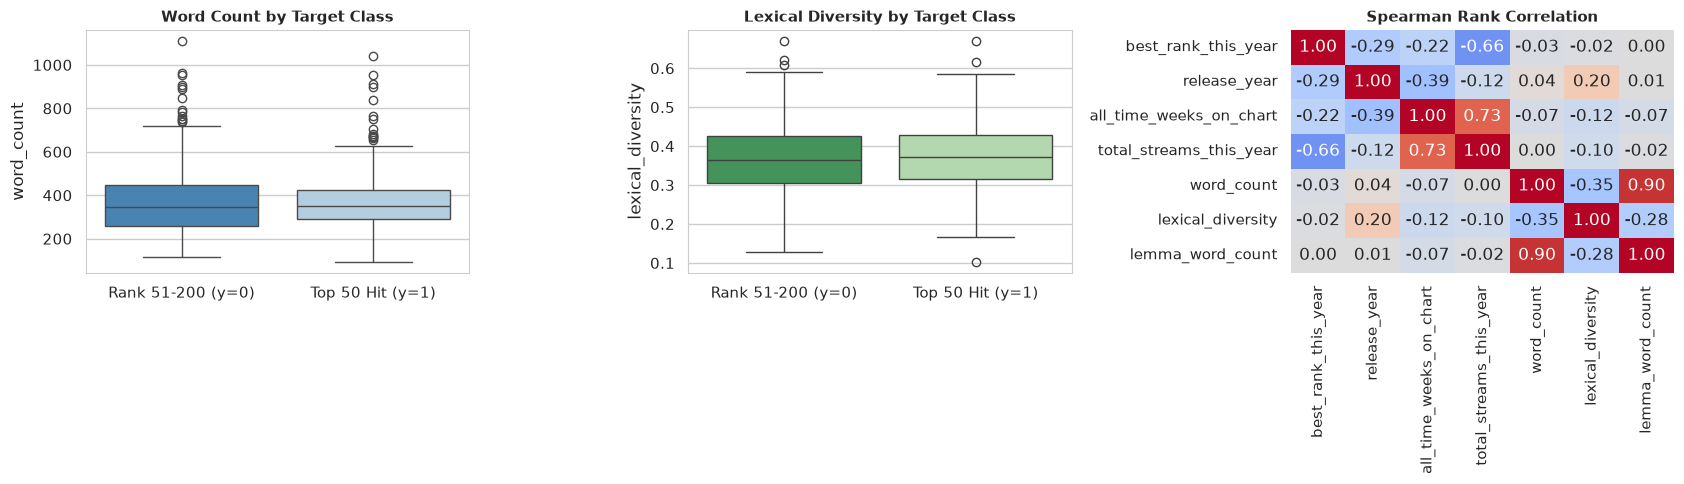

Word Count: Hit Mean = 375.1 vs Non-Hit Mean = 370.9 | p-value = 0.4488 (Not Significant)
Lexical Diversity: Hit Mean = 0.375 vs Non-Hit Mean = 0.368 | p-value = 0.3121 (Not Significant)
Collinearity Alert: Spearman r(word_count, lemma_word_count) = 0.904. Retain only one in ML models.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Target vs Word Count
sns.boxplot(data=df, x='target_hit', y='word_count', ax=axes[0], hue='target_hit', palette="Blues_r", legend=False)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Rank 51-200 (y=0)', 'Top 50 Hit (y=1)'])
axes[0].set_title("Word Count by Target Class", fontweight="bold")
axes[0].set_xlabel("")

# Target vs Lexical Diversity
sns.boxplot(data=df, x='target_hit', y='lexical_diversity', ax=axes[1], hue='target_hit', palette="Greens_r", legend=False)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Rank 51-200 (y=0)', 'Top 50 Hit (y=1)'])
axes[1].set_title("Lexical Diversity by Target Class", fontweight="bold")
axes[1].set_xlabel("")

# Spearman Correlation Matrix
corr_cols = ['best_rank_this_year', 'release_year', 'all_time_weeks_on_chart', 'total_streams_this_year', 'word_count', 'lexical_diversity', 'lemma_word_count']
corr_spearman = df[corr_cols].corr(method='spearman')
sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[2], cbar=False)
axes[2].set_title("Spearman Rank Correlation", fontweight="bold")

plt.tight_layout()
plt.show()

# Tests
hit_g = df[df['target_hit'] == 1]
reg_g = df[df['target_hit'] == 0]
_, p_wc = stats.mannwhitneyu(hit_g['word_count'], reg_g['word_count'])
_, p_div = stats.mannwhitneyu(hit_g['lexical_diversity'], reg_g['lexical_diversity'])

print(f"Word Count: Hit Mean = {hit_g['word_count'].mean():.1f} vs Non-Hit Mean = {reg_g['word_count'].mean():.1f} | p-value = {p_wc:.4f} (Not Significant)")
print(f"Lexical Diversity: Hit Mean = {hit_g['lexical_diversity'].mean():.3f} vs Non-Hit Mean = {reg_g['lexical_diversity'].mean():.3f} | p-value = {p_div:.4f} (Not Significant)")
print(f"Collinearity Alert: Spearman r(word_count, lemma_word_count) = {corr_spearman.loc['word_count', 'lemma_word_count']:.3f}. Retain only one in ML models.")

## 6. Machine Learning Blueprint: Sequence Constraints & Leak-Free Group CV

### 6-1. Token Length Audit for BERT
Standard BERT models (`bert-base-uncased`, `all-MiniLM-L6-v2`) enforce a maximum sequence length of 256 or 512 tokens.
In our 596-track corpus:
* Median word count is **341 words** ($\approx 450$ subword tokens).
* **89.8% of tracks exceed 190 words** ($\approx 256$ tokens), and 23.0% exceed 380 words ($\approx 512$ tokens).
* Directly truncating lyrics will eliminate trailing verses, bridges, and final hooks. Modeling must use **stanza-level chunk pooling** or **long-context transformers** (e.g., `ModernBERT`).

### 6-2. Zero-Leakage Artist Group Cross-Validation
To prevent models from memorizing artist identities, collaborating artists are decomposed and grouped into **203 disjoint graph connected components**. We verify with programmatic assertions that train-test artist overlap is strictly 0.

In [7]:
# 1. Token Length Percentiles
wc_p05, wc_p50, wc_p95 = df['word_count'].quantile([0.05, 0.50, 0.95])
exceed_190 = (df['word_count'] > 190).mean() * 100
exceed_380 = (df['word_count'] > 380).mean() * 100

print(f"Word Count Percentiles: p05 = {wc_p05:.0f} words | Median = {wc_p50:.0f} words | p95 = {wc_p95:.0f} words")
print(f"Tracks exceeding 256-token limit (~190 words): {exceed_190:.1f}%")
print(f"Tracks exceeding 512-token limit (~380 words): {exceed_380:.1f}%")

# 2. Build Artist Graph Connected Components
adj = defaultdict(set)
all_artists = set()
for s in df['artist_names']:
    parts = [a.strip() for a in s.split(',') if a.strip()]
    for p in parts:
        all_artists.add(p)
    for i in range(len(parts)):
        for j in range(i + 1, len(parts)):
            adj[parts[i]].add(parts[j])
            adj[parts[j]].add(parts[i])
        if len(parts) == 1:
            adj[parts[0]].add(parts[0])

visited = set()
artist_to_cluster = {}
cluster_counter = 0
for artist in all_artists:
    if artist not in visited:
        cluster_counter += 1
        q = deque([artist])
        visited.add(artist)
        while q:
            curr = q.popleft()
            artist_to_cluster[curr] = f"cluster_{cluster_counter}"
            for nbr in adj[curr]:
                if nbr not in visited:
                    visited.add(nbr)
                    q.append(nbr)

df['artist_cluster'] = df['artist_names'].apply(lambda s: artist_to_cluster[s.split(',')[0].strip()])

# 3. 5-Fold StratifiedGroupKFold
y = df['target_hit']
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

print("\n" + "=" * 80)
print(f"5-Fold StratifiedGroupKFold Split Verification (N = {len(df)}, Clusters = {cluster_counter})")
print("=" * 80)

for fold, (train_idx, test_idx) in enumerate(sgkf.split(df, y, groups=df['artist_cluster'])):
    train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
    train_artists = set(a.strip() for s in train_df['artist_names'] for a in s.split(','))
    test_artists = set(a.strip() for s in test_df['artist_names'] for a in s.split(','))
    overlap = train_artists.intersection(test_artists)
    assert len(overlap) == 0, f"Leakage detected in Fold {fold+1}!"
    print(f"Fold {fold+1}: Test Size = {len(test_idx):3d} | Test y=1 Mean = {y.iloc[test_idx].mean():.4f} | Artist Overlap = {len(overlap)}")

print("=" * 80)
print("Assertion Passed: Strictly 0% individual artist leakage across all folds.")

Word Count Percentiles: p05 = 173 words | Median = 349 words | p95 = 669 words
Tracks exceeding 256-token limit (~190 words): 92.6%
Tracks exceeding 512-token limit (~380 words): 40.3%

5-Fold StratifiedGroupKFold Split Verification (N = 596, Clusters = 203)
Fold 1: Test Size = 125 | Test y=1 Mean = 0.4080 | Artist Overlap = 0
Fold 2: Test Size = 119 | Test y=1 Mean = 0.3866 | Artist Overlap = 0
Fold 3: Test Size = 118 | Test y=1 Mean = 0.3814 | Artist Overlap = 0
Fold 4: Test Size = 117 | Test y=1 Mean = 0.3846 | Artist Overlap = 0
Fold 5: Test Size = 117 | Test y=1 Mean = 0.3846 | Artist Overlap = 0
Assertion Passed: Strictly 0% individual artist leakage across all folds.


# 6. Summary of Findings

### 1. Preprocessing Impact
* **Length Reduction:** Removing stopwords and lemmatizing reduces word counts by ~45% (`word_count` mean ~375 $\rightarrow$ `lemma_word_count` mean ~204).
* **Vocabulary Diversity Shift:** After removing repeated function words (`the`, `you`, `I`, `oh`), vocabulary diversity increases across all genres (`lexical_diversity` mean ~0.37 $\rightarrow$ `lemma_lexical_diversity` mean ~0.44).
* **Genre Patterns:** Hip-Hop/Rap has the longest lyrics (`word_count` mean ~495) while Country and Alternative have slightly higher vocabulary diversity than Pop and K-Pop.

---

### 2. Lyric Features vs. Chart Performance
* **Near-Zero Correlations with Chart Rank:** Both `word_count` and `lexical_diversity` have near-zero correlations ($|r| \le 0.08$) with `best_rank_this_year` and `all_time_weeks_on_chart`.
* **Why Genre Differences Appear in EDA:** While genres differ in lyric length, their chart performance differences in this 1-year window are mainly driven by **release timing** (older Rock classics vs. newer Pop/K-Pop releases) and **superstar fanbases** rather than lyric structure.

---

### 3. Next Step: Topic Modeling & Machine Learning Summary (`596` $\rightarrow$ `582` Songs)
* **Removing 14 Leftover Holiday Songs (`596` $\rightarrow$ `582`):** When we ran BERTopic on the 596 songs from this notebook, one topic cluster grouped together 14 leftover Christmas songs that had `track_type == 'standard'` or `'remix'` (such as *My Only Wish (This Year)*, *Run Rudolph Run*, and *Fairytale of New York*). Removing those 14 seasonal songs produced our final **582-song modeling dataset** (`Scripts/m1_bertopic_model.py`).
* **5-Fold Artist-Grouped Cross-Validation Results:** Using `StratifiedGroupKFold` (grouping by artist so the same artist never appears in both train and test sets) and standardizing `release_year` with `StandardScaler`:
  * **M1 Metadata Baseline (`Release Year + Genre`):** Mean ROC-AUC = **`0.6611`** (or **`0.5239`** when restricted to 2024–2026 releases, $N=316$).
  * **M2 Metadata + BERTopic Lyric Themes:** Mean ROC-AUC = **`0.6463`** (or **`0.5313`** on 2024–2026 releases).
  * **M3 Text Embeddings Only (`Sentence-BERT`) & M4 Basic Lyric Stats Only:** Mean ROC-AUC = **`0.5080`** and **`0.4696`** (no better than a 50/50 coin flip).
* **Final Conclusion:** Within the Spotify Global Top 200, basic lyric statistics and lyric themes do not predict Top 50 placement once release year and artist presence are accounted for.